# **Adzuna - Exploring the job-market data**

**Contents**

1. Loading the tables
2. Data quality: what is missing?
3. Where are the jobs?
4. Who is hiring?
5. Salaries
6. Time: posting dates and salary history
7. Keywords in titles and descriptions
8. How Adzuna fits our pipeline
9. Wrap-up

*Data: `python scripts/data/adzuna.py at "data engineer"` writes the CSV files in `data/adzuna/`. Re-run the script to refresh them.*

In [1]:
import re

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style = 'whitegrid')
BLUE, ORANGE = '#2a78d6', '#eb6834'   # one colour per job: BLUE = "how much", ORANGE = the second group

***

## **1. Loading the tables**

`adzuna.py` saves one table per API endpoint. `jobs` is the important one (one row per job ad); the other five are aggregates that Adzuna computes for us.

In [2]:
names = ['jobs', 'categories', 'salary_histogram', 'top_companies', 'geodata', 'salary_history']
tables = {name: pd.read_csv(f'../data/adzuna/{name}.csv') for name in names}

pd.DataFrame({'rows': {n: t.shape[0] for n, t in tables.items()},
              'columns': {n: t.shape[1] for n, t in tables.items()}})

,rows,columns
jobs,101,21
categories,30,5
salary_histogram,7,5
top_companies,5,5
geodata,8,6
salary_history,12,5


In [3]:
jobs = tables['jobs']
jobs['created'] = pd.to_datetime(jobs['created'])
jobs.head(3)

,title,description,created,id,adref,latitude,longitude,redirect_url,salary_is_predicted,company_display_name,...,location_area,category_tag,category_label,contract_time,salary_max,contract_type,salary_min,country,search,fetched_at
0,Junior Data Engineer,AT&S is a leading global manufacturer of high-...,2026-10-10 18:45:12+00:00,5922440213,eyJhbGciOiJIUzI1NiJ9.eyJzIjoiUXNzTVlDREg4UkdnT...,47.371210,15.085172,https://www.adzuna.at/land/ad/5922440213?se=Qs...,0,AT&S Austria Technologie & Systemtechnik AG,...,Österreich > Steiermark > Leoben > Leoben,unknown,Unknown,NaN,NaN,NaN,NaN,at,data engineer,2026-10-13T16:08:48+00:00
1,Senior Data Engineer (m/w/d),Die WALTER GROUP zählt mit mehr als 5.000 Mita...,2026-10-03 22:37:21+00:00,5910600529,eyJhbGciOiJIUzI1NiJ9.eyJzIjoiUXNzTVlDREg4UkdnT...,48.083676,16.318037,https://www.adzuna.at/land/ad/5910600529?se=Qs...,0,WALTER GROUP,...,Österreich > Niederösterreich > Mödling > Wien...,unknown,Unknown,NaN,NaN,NaN,NaN,at,data engineer,2026-10-13T16:08:48+00:00
2,Data Engineer (w/m/d),Unser Kunde ist ein weltweit führendes Entwick...,2026-10-02 18:50:21+00:00,5908478122,eyJhbGciOiJIUzI1NiJ9.eyJzIjoiUXNzTVlDREg4UkdnT...,48.208144,16.354031,https://www.adzuna.at/land/ad/5908478122?se=Qs...,0,STEINER-HITECH GmbH,...,Österreich > Wien,unknown,Unknown,NaN,NaN,NaN,NaN,at,data engineer,2026-10-13T16:08:48+00:00


Every table carries `country`, `search` and `fetched_at`, so several runs (other countries, other keywords, other days) can later be stacked with `pd.concat`.

In [4]:
jobs[['country', 'search', 'fetched_at']].drop_duplicates()

,country,search,fetched_at
0,at,data engineer,2026-10-13T16:08:48+00:00


***

## **2. Data quality: what is missing?**

Before any analysis: which columns can we actually rely on? A horizontal bar chart of the share of missing values per column answers that at a glance.

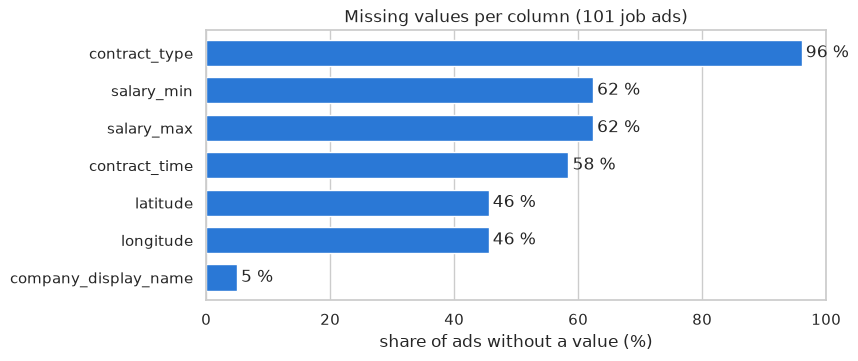

In [5]:
missing = jobs.isna().mean().mul(100).sort_values()
missing = missing[missing > 0]

ax = missing.plot.barh(figsize = (8, 3.5), color = BLUE, width = 0.7)
ax.bar_label(ax.containers[0], fmt = '%.0f %%', padding = 3)
ax.set_title(f'Missing values per column ({len(jobs)} job ads)')
ax.set_xlabel('share of ads without a value (%)')
ax.set_xlim(0, 100)
ax.grid(axis = 'y', visible = False)
plt.show()

Salary is missing for most ads and `contract_type` is almost never filled. Two more things a pipeline has to handle:

* **duplicates** - the same ad is published several times (other location, other recruiter),
* **junk salaries** - placeholder values like `1`.

In [6]:
print('ads with an identical description:', jobs.duplicated('description').sum())
print('ads with the same title and company:', jobs.duplicated(['title', 'company_display_name']).sum())
print('description length (characters):')
jobs['description'].str.len().describe()[['min', '50%', 'max']]

ads with an identical description: 16
ads with the same title and company: 17
description length (characters):


min    240.0
50%    500.0
max    500.0
Name: description, dtype: float64

The description is **cut off after 500 characters** by the API. That is the most important limitation for our keyword analysis: requirement lists usually come *after* the company introduction, so most of them are not in this text. The full text is only on the page behind `redirect_url`.

In [7]:
jobs.loc[jobs['salary_min'].notna(), ['title', 'salary_min', 'salary_max']].sort_values('salary_min').iloc[[0, 1, -2, -1]]

,title,salary_min,salary_max
45,Data & Monitoring Engineer (m/w/d),1.0,1.0
56,"Senior Backend Engineer (Data, Search, Infrast...",60.0,90.0
58,Platform Engineer (AI / Data Platform),104000.0,117000.0
96,Systems Architect,131376.0,243984.0


In [8]:
# cleaned copy used from here on: no placeholder salaries, one mid-point per ad
jobs['salary_mid'] = jobs[['salary_min', 'salary_max']].mean(axis = 1)
jobs.loc[jobs['salary_min'] < 10_000, 'salary_mid'] = np.nan
jobs['salary_mid'].notna().sum()

np.int64(35)

***

## **3. Where are the jobs?**

The `geodata` endpoint counts the ads per region. A sorted bar chart is the right choice for comparing a number across categories.

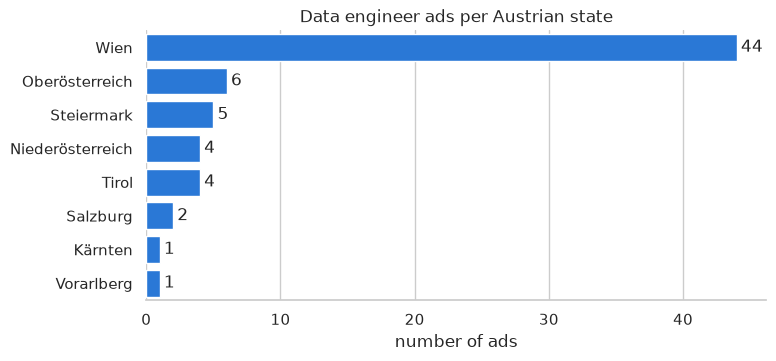

In [9]:
geo = tables['geodata'].copy()
geo['region'] = geo['location_area'].str.split(' > ').str[-1]

ax = sns.barplot(x = 'count', y = 'region', data = geo, color = BLUE, saturation = 1)
ax.bar_label(ax.containers[0], padding = 3)
ax.figure.set_size_inches(8, 3.5)
ax.set_title('Data engineer ads per Austrian state')
ax.set_xlabel('number of ads')
ax.set_ylabel('')
ax.grid(axis = 'y', visible = False)
sns.despine(left = True)
plt.show()

Vienna dominates. The `jobs` table also has `latitude` / `longitude` for about half of the ads, enough for a map later on.

***

## **4. Who is hiring?**

The `top_companies` endpoint only returns five employers, so we count the companies in the `jobs` table ourselves.

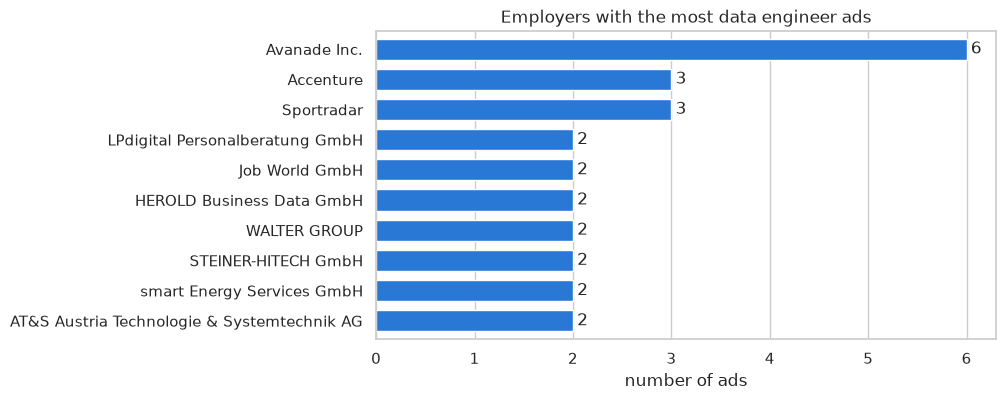

In [10]:
companies = jobs['company_display_name'].value_counts().head(10).sort_values()

ax = companies.plot.barh(figsize = (8, 4), color = BLUE, width = 0.7)
ax.bar_label(ax.containers[0], padding = 3)
ax.set_title('Employers with the most data engineer ads')
ax.set_xlabel('number of ads')
ax.set_ylabel('')
ax.grid(axis = 'y', visible = False)
plt.show()

Note the recruiters in the list (personnel consultancies post on behalf of a client), and that the same company appears under different spellings in `jobs` (`Avanade Inc.`) and `top_companies` (`Avanade`). For the CEO story (what are competitors looking for?) employer names need normalizing.

***

## **5. Salaries**

Adzuna gives us salaries twice: as a ready-made histogram (endpoint `histogram`) and as `salary_min` / `salary_max` per ad.

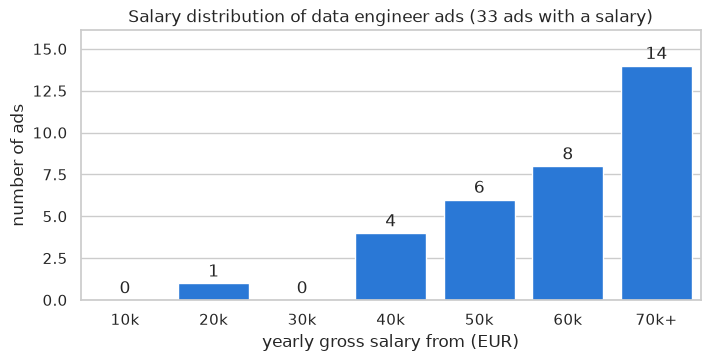

In [11]:
hist = tables['salary_histogram'].copy()
hist['bucket'] = (hist['salary_from'] // 1000).astype(str) + 'k'
hist.loc[hist.index[-1], 'bucket'] += '+'      # the last bucket is open-ended

ax = sns.barplot(x = 'bucket', y = 'ad_count', data = hist, color = BLUE, saturation = 1)
ax.bar_label(ax.containers[0], padding = 2)
ax.figure.set_size_inches(8, 3.5)
ax.set_title(f"Salary distribution of data engineer ads ({hist['ad_count'].sum()} ads with a salary)")
ax.set_xlabel('yearly gross salary from (EUR)')
ax.set_ylabel('number of ads')
ax.set_ylim(0, hist['ad_count'].max() * 1.15)
ax.grid(axis = 'x', visible = False)
plt.show()

With the per-ad values we can split by anything we derive ourselves, for example **seniority** taken from the title. Because there are so few ads with a salary, we show every single ad as a point on top of the box plot.

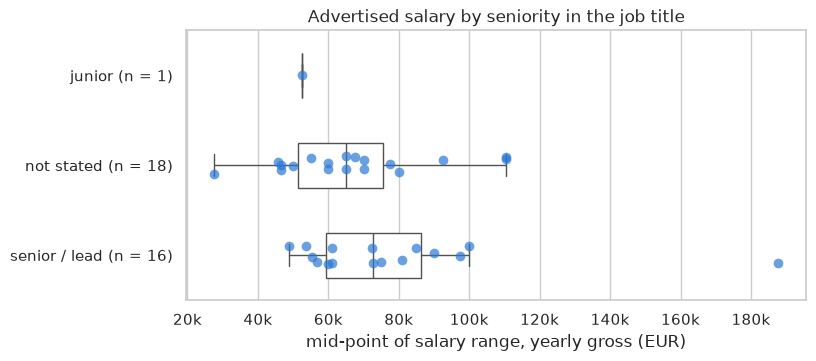

In [12]:
title = jobs['title'].str.lower()
jobs['seniority'] = np.select(
    [title.str.contains(r'junior|trainee|praktik|intern\b'),
     title.str.contains(r'senior|lead|principal|architect|head')],
    ['junior', 'senior / lead'], default = 'not stated')

paid = jobs.dropna(subset = 'salary_mid')
order = ['junior', 'not stated', 'senior / lead']
counts = paid['seniority'].value_counts()

fig, ax = plt.subplots(figsize = (8, 3.5))
sns.boxplot(x = 'salary_mid', y = 'seniority', data = paid, order = order, color = 'white',
            width = 0.5, fliersize = 0, linecolor = '#52514e', ax = ax)
sns.stripplot(x = 'salary_mid', y = 'seniority', data = paid, order = order, color = BLUE,
              size = 7, alpha = 0.7, ax = ax)
ax.set_yticks(range(len(order)), [f'{o} (n = {counts.get(o, 0)})' for o in order])
ax.set_title('Advertised salary by seniority in the job title')
ax.set_xlabel('mid-point of salary range, yearly gross (EUR)')
ax.set_ylabel('')
ax.xaxis.set_major_formatter(lambda x, _: f'{x / 1000:.0f}k')
plt.show()

The direction is as expected, but with a handful of ads per group this is an illustration of the method, not a result. In Austria the advertised figure is usually the legal *minimum* salary ("ab EUR ..."), so it understates real pay.

***

## **6. Time: posting dates and salary history**

`created` is the date an ad was posted. Resampling by week (Block 5) shows when the currently live ads went online.

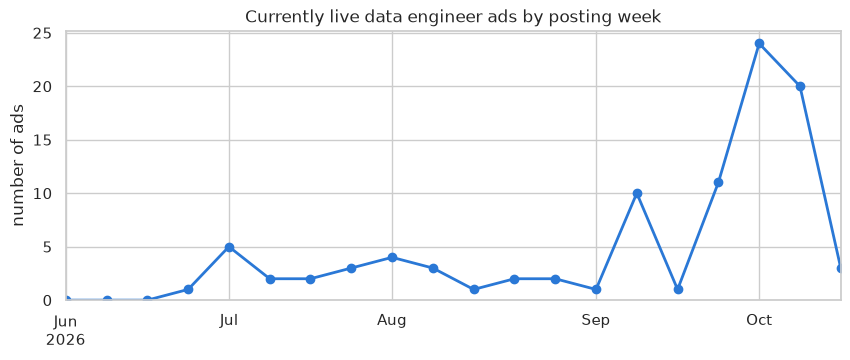

In [13]:
weekly = jobs.set_index('created').resample('W')['id'].count().loc['2026-06':]

ax = weekly.plot(figsize = (10, 3.5), color = BLUE, linewidth = 2, marker = 'o')
ax.set_title('Currently live data engineer ads by posting week')
ax.set_xlabel('')
ax.set_ylabel('number of ads')
ax.set_ylim(0)
plt.show()

**This is not demand over time.** We only see ads that are *still online today*; older ads have already been taken down, so the curve always rises towards the present. To measure demand over time we have to **collect a snapshot regularly** (e. g. weekly) and compare the snapshots - that is what the `fetched_at` column is for.

The only real history Adzuna offers is the `history` endpoint: the monthly mean advertised salary. In our call it covers *all* jobs in Austria, not only data engineers.

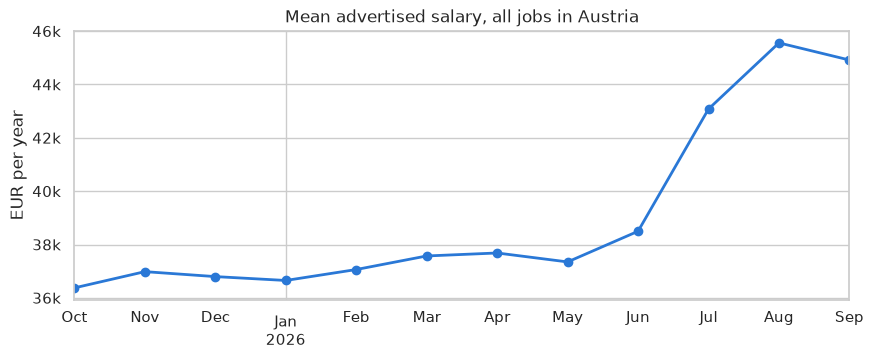

In [14]:
history = tables['salary_history'].copy()
history['month'] = pd.to_datetime(history['month'])
history = history.set_index('month')['mean_salary']

ax = history.plot(figsize = (10, 3.5), color = BLUE, linewidth = 2, marker = 'o')
ax.set_title('Mean advertised salary, all jobs in Austria')
ax.set_xlabel('')
ax.set_ylabel('EUR per year')
ax.yaxis.set_major_formatter(lambda y, _: f'{y / 1000:.0f}k')
plt.show()

The jump in summer 2026 is too large to be a real change in wages within one month - more likely the mix of ads or Adzuna's method changed. Worth checking against Eurostat before using it.

***

## **7. Keywords in titles and descriptions**

A first, simple version of the keyword analysis: a hand-written dictionary of skills, each with a regular expression and a group (*AI-related* or *traditional*), and `str.contains()` to flag the ads that mention it.

In [15]:
skills = pd.DataFrame([
    # skill,              pattern,                                              group
    ('Python',            r'\bpython\b',                                        'traditional'),
    ('SQL',               r'\bsql\b',                                           'traditional'),
    ('Java',              r'\bjava\b',                                          'traditional'),
    ('Spark',             r'\b(?:py)?spark\b',                                  'traditional'),
    ('Kafka',             r'\bkafka\b',                                         'traditional'),
    ('Airflow',           r'\bairflow\b',                                       'traditional'),
    ('dbt',               r'\bdbt\b',                                           'traditional'),
    ('ETL / pipelines',   r'\betl\b|\belt\b|pipeline',                         'traditional'),
    ('Azure',             r'\bazure\b',                                         'traditional'),
    ('AWS',               r'\baws\b',                                           'traditional'),
    ('Databricks',        r'\bdatabricks\b',                                    'traditional'),
    ('Snowflake',         r'\bsnowflake\b',                                     'traditional'),
    ('Microsoft Fabric',  r'\bfabric\b',                                        'traditional'),
    ('Power BI / BI',     r'\bpower ?bi\b|\bbi\b',                             'traditional'),
    ('SAP',               r'\bsap\b',                                           'traditional'),
    ('Cloud',             r'\bcloud\b',                                         'traditional'),
    ('Kubernetes/Docker', r'\bkubernetes\b|\bdocker\b',                        'traditional'),
    ('AI / KI',           r'\b(?-i:AI|KI)\b|artificial intelligence|künstliche intelligenz', 'AI-related'),
    ('Machine learning',  r'machine learning|\b(?-i:ML)\b|\bmlops\b',           'AI-related'),
    ('LLM / GenAI',       r'\bllms?\b|large language model|\bgen ?ai\b|generativ', 'AI-related'),
    ('Computer vision',   r'computer vision',                                   'AI-related'),
    ('Agents',            r'\bagent(?:s|ic|en)?\b',                              'AI-related'),
], columns = ['skill', 'pattern', 'group'])

unique = jobs.drop_duplicates('description')       # count every ad text only once
text = unique['title'] + ' ' + unique['description']
matches = pd.DataFrame({s.skill: text.str.contains(s.pattern, case = False, regex = True)
                        for s in skills.itertuples()})
matches.head()

,Python,SQL,Java,Spark,Kafka,Airflow,dbt,ETL / pipelines,Azure,AWS,...,Microsoft Fabric,Power BI / BI,SAP,Cloud,Kubernetes/Docker,AI / KI,Machine learning,LLM / GenAI,Computer vision,Agents
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,True,True,False,False,False,False,False,True,False,True,...,False,False,False,True,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


`matches` has one row per ad and one boolean column per skill - exactly the shape of the `job_posting_skills` table in our data model (after `melt()`). The mean of a boolean column is the share of ads mentioning the skill.

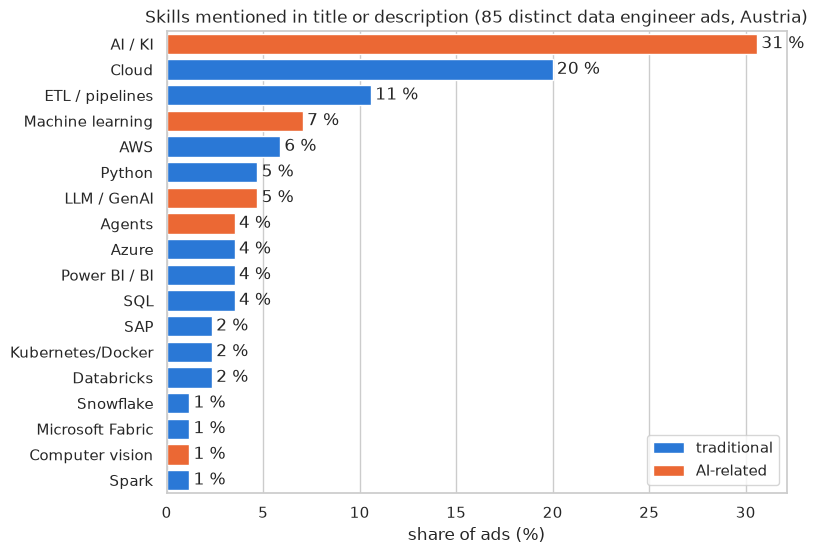

In [16]:
share = (matches.mean().mul(100).rename_axis('skill').reset_index(name = 'share')
         .merge(skills[['skill', 'group']]).sort_values('share', ascending = False))
share = share[share['share'] > 0]

fig, ax = plt.subplots(figsize = (8, 6))
sns.barplot(x = 'share', y = 'skill', hue = 'group', data = share, dodge = False,
            hue_order = ['traditional', 'AI-related'], palette = [BLUE, ORANGE], saturation = 1, ax = ax)
for container in ax.containers:
    ax.bar_label(container, fmt = '%.0f %%', padding = 3)
ax.set_title(f'Skills mentioned in title or description ({len(unique)} distinct data engineer ads, Austria)')
ax.set_xlabel('share of ads (%)')
ax.set_ylabel('')
ax.legend(title = '', loc = 'lower right')
ax.grid(axis = 'y', visible = False)
plt.show()

In [17]:
ai_cols = skills.loc[skills['group'] == 'AI-related', 'skill']
mentions_ai = matches[ai_cols].any(axis = 1)
in_title = unique['title'].str.contains('|'.join(skills.loc[skills['group'] == 'AI-related', 'pattern']), case = False, regex = True)
print(f"{mentions_ai.mean():.0%} of the distinct ads mention at least one AI-related keyword")
print(f"{in_title.mean():.0%} have one in the job title itself")

33% of the distinct ads mention at least one AI-related keyword
19% have one in the job title itself


This number is the seed of the answer to "*to what extent are AI tasks redefining data engineering job descriptions?*" - once we have it per month, per country and per role, it becomes a trend line.

Keep the limits in mind:

* the text is the title plus the **first 500 characters** only, so every share is an **underestimate**,
* the ads are a mix of **German and English**, so patterns need both languages (`AI` / `KI`),
* a mention is not a requirement: many hits are **company boilerplate** ("... Data & AI und Security ...") and not a task of the job, which is why the share in the *title* is the more conservative number,
* repeated ads would count the same boilerplate several times, hence the `drop_duplicates()` above,
* short keywords are ambiguous (`BI`, `ML`, `agent`).

Always read a few matches in context before trusting a pattern:

In [18]:
pd.set_option('display.max_colwidth', 120)
ai_pattern = skills.set_index('skill').loc['AI / KI', 'pattern']
text[matches['AI / KI']].str.extract(f'(.{{0,40}}(?:{ai_pattern}).{{0,40}})', flags = re.IGNORECASE)[0].sample(8, random_state = 1)

80    orkplace, Business Applications, Data & AI und Security und legen Wert auf unsere 
65                                     Senior AI Software Engineer (w/m/div.) Job Descri
74          MLOps Engineer Für ein Enterprise-KI-Projekt wird ein erfahrener MLOps Engin
23                          Data Scientist /​ AI Engineer (d/​m/​f) The ams OSRAM Group 
95                                  Principal AI Engineer (f/m/x) Our hearts are burning
59    e ÖBB auf ihrem Weg zu einer Daten- und KI-getriebenen Organisation. Unsere Aufgab
83                                            AI Large Language Model (LLM) Technology A
84    p, and operate the machine learning and AI solutions at the core of SmartStream's 
Name: 0, dtype: str

***

## **8. How Adzuna fits our pipeline**

Mapping of the Adzuna columns to the `job_postings` table of our data model:

| our column | Adzuna column | comment |
|---|---|---|
| `external_posting_id` | `id` | stable key, use it to de-duplicate between snapshots |
| `title_raw` | `title` | source for `role_id` and `seniority` (section 5) |
| `employer_name` | `company_display_name` | needs normalizing, contains recruiters |
| `country_id`, `region_name`, `city_name` | `country`, `location_area` | split on ` > ` |
| `posted_date_id` | `created` | |
| `collected_at` | `fetched_at` | one value per snapshot |
| `description_text` | `description` | **truncated to 500 characters** |
| `salary_min_local`, `salary_max_local` | `salary_min`, `salary_max` | missing for most ads; check `salary_is_predicted` |
| `employment_type` | `contract_time`, `contract_type` | sparse |
| `source_url` | `redirect_url` | |
| `remote_type`, `currency_code`, `salary_period` | - | not provided; currency follows from the country |

What Adzuna is good for in our user stories:

* **comparison across countries and roles** (stories 2, 6): one cheap call per country and keyword returns the number of ads and the mean salary,
* **current skill demand** (stories 3, 5): keyword shares as in section 7,
* **salary by skill or seniority** (story 3): possible, but only for the minority of ads with a salary.

What it cannot do alone:

* **change over time**: there is no history of postings. Either we collect snapshots ourselves from now on, or we take the past from the LinkedIn 2023-2024 dataset and Eurostat and use Adzuna as the "today" data point,
* **full requirement lists**: only the first 500 characters of each ad.

***

## **9. Wrap-up**

* `adzuna.py` gives us six tidy tables; `jobs` is the one that feeds `job_postings`.
* Reliable: title, company, location, posting date, category. Sparse: salary, contract type. Truncated: description.
* The plots in sections 3 to 5 work today; sections 6 and 7 become meaningful once we collect more than one snapshot, more than one role and more than one country.

Next steps: run the script for more roles (`data scientist`, `software engineer`, `machine learning engineer`) and countries (`de`, `gb`, `us`), keep every snapshot instead of overwriting it, and extend the skill dictionary.